Оптимальная нагрузка: 10 показов/день | Прибыль: 1,530.00 млн руб.
Нагрузка  0: Реклама=   0.0M | Подписка=1500.0M | Потери=    0.0M | Прибыль=  1500.0M
Нагрузка 10: Реклама=  30.0M | Подписка=1500.0M | Потери=    0.0M | Прибыль=  1530.0M
Нагрузка 20: Реклама=  60.0M | Подписка=1470.0M | Потери=  920.0M | Прибыль=   610.0M
Нагрузка 30: Реклама=  90.0M | Подписка=1425.0M | Потери= 2300.0M | Прибыль=  -785.0M
Нагрузка 40: Реклама= 120.0M | Подписка=1350.0M | Потери= 4600.0M | Прибыль= -3130.0M
Нагрузка 50: Реклама= 150.0M | Подписка=1230.0M | Потери= 8280.0M | Прибыль= -6900.0M
Нагрузка 60: Реклама= 180.0M | Подписка=1050.0M | Потери=13800.0M | Прибыль=-12570.0M


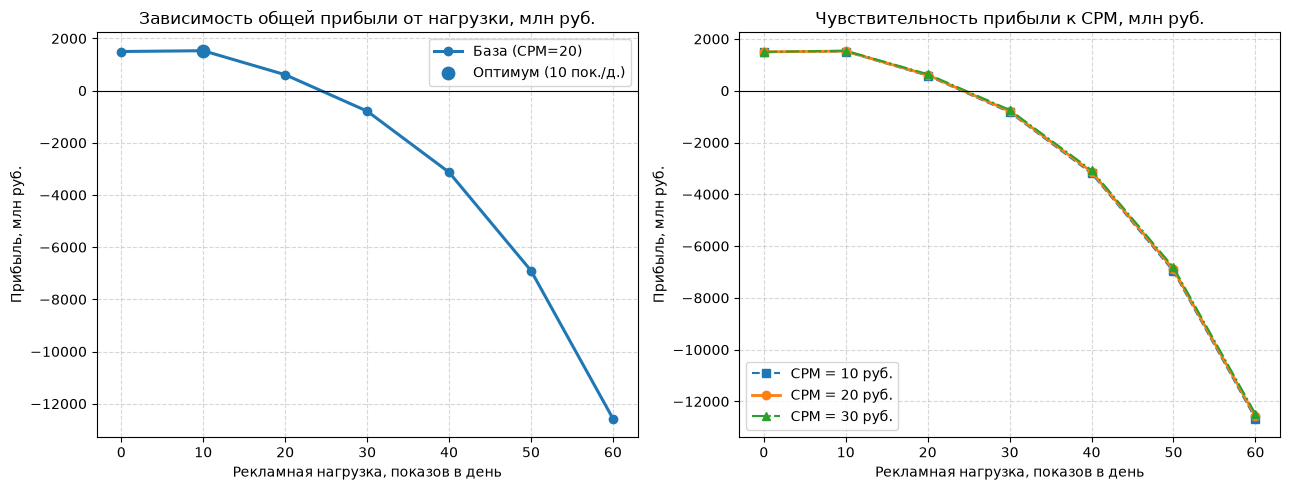

In [1]:
import matplotlib.pyplot as plt
import numpy as np

# ==========================================
# 1. ИСХОДНЫЕ ДАННЫЕ (Задание 4: ВидеоСервис)
# ==========================================
users = 5_000_000
sub_price = 300
cpm_base = 20
cac = 2_000
lifetime_months = 24

loads = [0, 10, 20, 30, 40, 50, 60]
churn_rates = [0.00, 0.00, 0.02, 0.05, 0.10, 0.18, 0.30]
watch_time = [120, 115, 110, 100, 90, 75, 60]


def calc_metrics(cpm_val=cpm_base, churn_mult=1.0):
  ad_rev_m, sub_rev_m, loss_m, profit_m = [], [], [], []
  for load, ch in zip(loads, churn_rates):
    eff_ch = min(1.0, max(0.0, ch * churn_mult))
    churn_users = users * eff_ch
    ad_rev = users * load * 30 * cpm_val / 1000.0
    sub_rev = (users - churn_users) * sub_price
    loss = churn_users * cac + (churn_users * sub_price * lifetime_months)
    total_profit = ad_rev + sub_rev - loss

    ad_rev_m.append(ad_rev / 1e6)
    sub_rev_m.append(sub_rev / 1e6)
    loss_m.append(loss / 1e6)
    profit_m.append(total_profit / 1e6)
  return ad_rev_m, sub_rev_m, loss_m, profit_m


# ==========================================
# 2. РАСЧЁТ И ВЫВОД РЕЗУЛЬТАТОВ
# ==========================================
ad_m, sub_m, loss_m, profit_m = calc_metrics(cpm_base, 1.0)
best_idx = int(np.argmax(profit_m))

print(
    f"Оптимальная нагрузка: {loads[best_idx]} показов/день | "
    f"Прибыль: {profit_m[best_idx]:,.2f} млн руб."
)
for l, a, s, lo, p in zip(loads, ad_m, sub_m, loss_m, profit_m):
  print(
      f"Нагрузка {l:2d}: Реклама={a:6.1f}M | Подписка={s:6.1f}M | "
      f"Потери={lo:7.1f}M | Прибыль={p:8.1f}M"
  )

_, _, _, profit_cpm10 = calc_metrics(10, 1.0)
_, _, _, profit_cpm30 = calc_metrics(30, 1.0)

# ==========================================
# 3. ГРАФИКИ И СОХРАНЕНИЕ В Zadanie_4_grafik.png
# ==========================================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# Левый график: прибыль в зависимости от рекламной нагрузки
ax1.plot(loads, profit_m, marker="o", linewidth=2.2, label="База (CPM=20)")
ax1.scatter(
    [loads[best_idx]],
    [profit_m[best_idx]],
    s=80,
    zorder=5,
    label=f"Оптимум ({loads[best_idx]} пок./д.)",
)
ax1.axhline(0, color="black", linewidth=0.8)
ax1.set_title("Зависимость общей прибыли от нагрузки, млн руб.")
ax1.set_xlabel("Рекламная нагрузка, показов в день")
ax1.set_ylabel("Прибыль, млн руб.")
ax1.legend()
ax1.grid(True, linestyle="--", alpha=0.5)

# Правый график: чувствительность прибыли к CPM (10, 20, 30 руб.)
ax2.plot(loads, profit_cpm10, marker="s", linestyle="--", label="CPM = 10 руб.")
ax2.plot(loads, profit_m, marker="o", linewidth=2, label="CPM = 20 руб.")
ax2.plot(loads, profit_cpm30, marker="^", linestyle="-.", label="CPM = 30 руб.")
ax2.axhline(0, color="black", linewidth=0.8)
ax2.set_title("Чувствительность прибыли к CPM, млн руб.")
ax2.set_xlabel("Рекламная нагрузка, показов в день")
ax2.set_ylabel("Прибыль, млн руб.")
ax2.legend()
ax2.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.savefig("Zadanie_4_grafik.png", dpi=300, bbox_inches="tight")
plt.show()